# 2 — Modèle bayésien de corrélation et validation

**Question :** parmi les alertes précédentes, lesquelles ressemblent suffisamment à la nouvelle alerte pour être proposées comme liées ? Le modèle renvoie une probabilité pour chaque paire candidate.

**Limite à garder en tête :** AIT-ADS annote des fenêtres de phases d’attaque, mais ne fournit pas de liens de référence entre paires d’alertes. Le label positif utilisé ici est donc faible : les deux alertes de la paire tombent dans une fenêtre de phase du même scénario.

## 1. Du flux d’alertes à des paires candidates

Pour chaque alerte courante `a_t`, on regarde un historique récent `H_t`. Pour maîtriser le coût, le prototype garde au plus 50 alertes récentes, limite l’écart à 30 minutes et retient jusqu’à cinq candidates diverses (plus récente, même hôte, autre détecteur, même signature, etc.). Les labels ne servent **pas** à choisir les candidates.

Une paire candidate est donc `(a_i, a_t)` : une alerte précédente et l’alerte courante. L’objectif du modèle est de scorer cette paire, pas de classer chaque événement isolément.

In [1]:
from pathlib import Path
from html import escape
import sys, json
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path.cwd()
if not (ROOT / 'src' / 'alert_correlation').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from alert_correlation.core import (
    load_alerts, iter_candidate_pairs, pair_features, fit_beta_bernoulli,
    posterior_feature_table, select_threshold_by_scenario_cv, score_pair,
    evaluate, save_json, TRAIN_SCENARIOS, TEST_SCENARIOS, FEATURES,
)
ALERTS = load_alerts(ROOT / 'artifacts' / 'alert_correlation' / 'normalized_alerts.csv')
MODEL_PATH = ROOT / 'artifacts' / 'alert_correlation' / 'bayesian_alert_correlation_model.json'
METRICS_PATH = ROOT / 'artifacts' / 'alert_correlation' / 'validation_metrics.json'
print(f'{len(ALERTS):,} alertes chargées')
print('Entraînement :', TRAIN_SCENARIOS, '| Test final :', TEST_SCENARIOS)

def show_table(headers, body):
    head = ''.join(f'<th>{escape(str(h))}</th>' for h in headers)
    rows = ''.join('<tr>' + ''.join(f'<td>{escape(str(v))}</td>' for v in row) + '</tr>' for row in body)
    display(HTML(f'<table><thead><tr>{head}</tr></thead><tbody>{rows}</tbody></table>'))

207,583 alertes chargées
Entraînement : ['shaw', 'wardbeck'] | Test final : ['russellmitchell']


In [2]:
# Petit exemple pédagogique : une alerte précédente et une alerte courante.
example = sorted(
    [a for a in ALERTS if a['scenario'] == TRAIN_SCENARIOS[0]],
    key=lambda a: a['timestamp_epoch']
)
example_pair = pair_features(example[0], example[1])
show_table(['Indice de paire', 'Valeur de l’exemple', 'Lecture'], [
    ['same_host', example_pair['same_host'], '1 signifie même hôte renseigné'],
    ['same_detector', example_pair['same_detector'], '1 signifie même détecteur'],
    ['same_signature', example_pair['same_signature'], '1 signifie même signature'],
    ['gap_le_10s', example_pair['gap_le_10s'], '1 signifie écart ≤ 10 secondes'],
    ['gap_le_60s', example_pair['gap_le_60s'], '1 signifie écart ≤ 60 secondes'],
])

Indice de paire,Valeur de l’exemple,Lecture
same_host,1,1 signifie même hôte renseigné
same_detector,1,1 signifie même détecteur
same_signature,0,1 signifie même signature
gap_le_10s,1,1 signifie écart ≤ 10 secondes
gap_le_60s,1,1 signifie écart ≤ 60 secondes


## 2. Les variables et la cible

Chaque paire est décrite par cinq variables binaires `x_f` :

- `same_host` : les alertes nomment le même hôte ;
- `same_detector` : elles viennent du même détecteur ;
- `same_signature` : elles portent la même signature ;
- `gap_le_10s` et `gap_le_60s` : l’écart entre leurs temps est inférieur au délai indiqué.

La cible `c=1` signifie seulement que les deux alertes tombent dans une fenêtre de phase annotée ; `c=0` signifie que ce n’est pas le cas. Ce n’est pas une vérité terrain de lien entre deux alertes.

## 3. Comment fonctionne le calcul bayésien ?

Pour chaque indice `f` et chaque classe `c`, le modèle estime `θ[f,c] = P(x_f=1 | c)`, c’est-à-dire la fréquence de présence de cet indice dans cette classe.

**Prior :** `θ[f,c] ~ Beta(α, β)`, avec `α=1` et `β=1`. La loi Beta(1,1) est uniforme : avant les exemples, aucune probabilité de 0 à 1 n’est favorisée.

**Après les observations :** si `s` des `n` paires de classe `c` possèdent l’indice, alors `θ[f,c] | données ~ Beta(α+s, β+n−s)`. La probabilité prédictive utilisée par le code est sa moyenne : `(α+s)/(α+β+n)`.

**Prior de classe :** le modèle lisse aussi la fréquence des paires positives : `π=P(c=1)=(N₁+α)/(N₀+N₁+α+β)` et `P(c=0)=1−π`, où `N₀,N₁` sont les nombres de paires d’entraînement de chaque classe. **Bayes pour la paire :** `P(c | x) ∝ P(c) × P(x | c)`. Le modèle suppose les indices indépendants une fois la classe connue, donc `P(x | c) ≈ ∏f θ[f,c]^x_f (1−θ[f,c])^(1−x_f)`. Pour les deux classes, pose `L_c=P(c)P(x|c)`. Le score final est `P(c=1|x)=L₁/(L₀+L₁)` : le numérateur représente le soutien à la classe positive, et le dénominateur normalise les deux possibilités pour obtenir une probabilité entre 0 et 1. Le code additionne les logarithmes de ces facteurs pour éviter les nombres trop petits.

**Symboles :** `f` = indice ; `c` = classe de paire ; `x_f∈{0,1}` = indice observé ; `θ` = probabilité d’un indice ; `s` = nombre de présences ; `n` = nombre de paires de la classe ; `N_c` = nombre de paires de classe `c` ; `π` = prior de classe ; `α,β` = paramètres du prior Beta. Ici, `α` et `β` ne sont pas des coefficients de régression.

Cette mise à jour Beta–Bernoulli a une solution analytique. Il n’y a ni logit ni MCMC dans ce modèle.

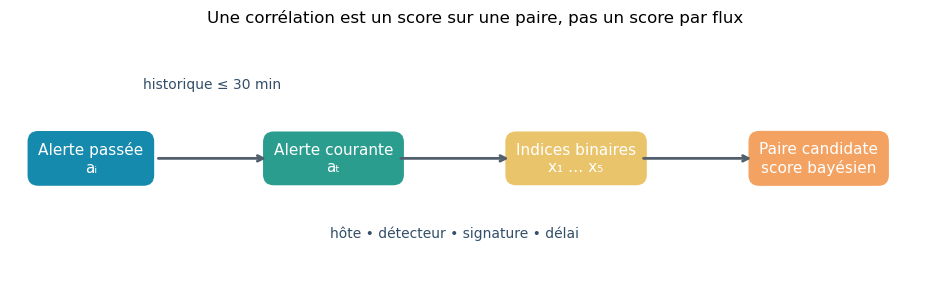

In [6]:
# Schéma de la construction : le temps choisit des candidates, les champs créent x_f.
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 3); ax.axis('off') # Increased xlim to 11.5

# Added line breaks (\n) and shifted the last item to x=10
items = [
    (1, 'Alerte passée\naᵢ'), 
    (4, 'Alerte courante\naₜ'), 
    (7, 'Indices binaires\nx₁ … x₅'), 
    (10, 'Paire candidate\nscore bayésien')
]
colors = ['#168aad', '#2a9d8f', '#e9c46a', '#f4a261']

for (x, label), color in zip(items, colors):
    ax.text(x, 1.6, label, ha='center', va='center', fontsize=11, color='white',
            bbox=dict(boxstyle='round,pad=.7', facecolor=color, edgecolor='none'))

# Adjusted arrow positions to match the evenly spaced boxes
for x1, x2 in [(1.8, 3.2), (4.8, 6.2), (7.8, 9.2)]:
    ax.annotate('', xy=(x2,1.6), xytext=(x1,1.6), 
                arrowprops=dict(arrowstyle='->', lw=2, color='#52606d'))

# Slightly adjusted vertical spacing for the descriptive text
ax.text(2.5, 2.4, 'historique ≤ 30 min', ha='center', color='#334e68')
ax.text(5.5, 0.7, 'hôte • détecteur • signature • délai', ha='center', color='#334e68')

ax.set_title('Une corrélation est un score sur une paire, pas un score par flux', pad=10)
plt.show()

## 4. Ajuster les fréquences et lire la matrice des indices

Les comptes d’entraînement donnent, pour chaque indice, la proportion prédictive estimée dans les paires positives et négatives **selon le label faible**. La heatmap ci-dessous est une matrice `indice × classe`; elle ne mesure pas une causalité et ne montre pas des liens validés.

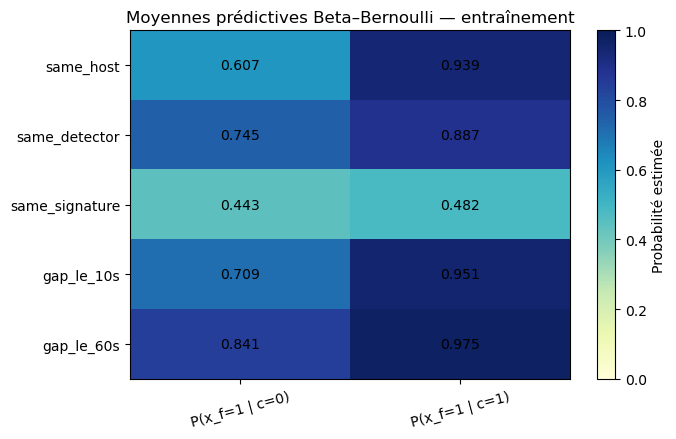

Indice,P(indice présent | c=0),P(indice présent | c=1)
same_host,0.607,0.939
same_detector,0.745,0.887
same_signature,0.443,0.482
gap_le_10s,0.709,0.951
gap_le_60s,0.841,0.975


In [7]:
model = fit_beta_bernoulli(ALERTS, TRAIN_SCENARIOS)
feature_rows = posterior_feature_table(model)
class0_key = 'P(feature=1 | class=0)'
class1_key = 'P(feature=1 | class=1)'
heat = [[row[class0_key], row[class1_key]] for row in feature_rows]

fig, ax = plt.subplots(figsize=(7, 4.5))
image = ax.imshow(heat, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks([0,1], ['P(x_f=1 | c=0)', 'P(x_f=1 | c=1)'])
ax.set_yticks(range(len(feature_rows)), [r['feature'] for r in feature_rows])
ax.tick_params(axis='x', labelrotation=15)
for i, row in enumerate(heat):
    for j, value in enumerate(row):
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', color='black')
ax.set_title('Moyennes prédictives Beta–Bernoulli — entraînement')
fig.colorbar(image, ax=ax, label='Probabilité estimée')
fig.tight_layout()
plt.show()

show_table(['Indice', 'P(indice présent | c=0)', 'P(indice présent | c=1)'],
           [[r['feature'], f"{r[class0_key]:.3f}", f"{r[class1_key]:.3f}"] for r in feature_rows])

## 5. Choisir le seuil sans regarder le scénario de test

Une probabilité devient un lien proposé si elle dépasse le seuil. Un seuil bas tend à retrouver davantage de paires positives faibles (rappel élevé), mais augmente aussi les liens proposés à tort (baisse de précision).

Le seuil est choisi par validation croisée **uniquement sur Shaw et Wardbeck** : à chaque fold, un scénario d’entraînement est laissé de côté ; le seuil qui maximise le F1 sur ces prédictions est retenu. Le scénario RussellMitchell ne participe ni à l’apprentissage ni au choix du seuil.

In [9]:
threshold_choice = select_threshold_by_scenario_cv(ALERTS, TRAIN_SCENARIOS)
model['decision_threshold'] = threshold_choice['threshold']
model['threshold_selection'] = threshold_choice
model['label_caveat'] = 'Weak pair labels: both alerts fall inside AIT-ADS attack-phase windows; no analyst-confirmed pair links.'
save_json(MODEL_PATH, model)
print('Résultat CV sur les seuls scénarios train :')
print(json.dumps(threshold_choice, indent=2, ensure_ascii=False))
print(f"Seuil retenu : {model['decision_threshold']:.2f}")

Résultat CV sur les seuls scénarios train :
{
  "threshold": 0.04,
  "F1": 0.21935335988440868,
  "precision": 0.12431682580333862,
  "recall": 0.9313197316742553,
  "oof_pairs": 373649,
  "method": "Leave-one-scenario-out predictions within training scenarios; maximize F1 on a fixed 0.01 threshold grid."
}
Seuil retenu : 0.04


## 6. Test final sur RussellMitchell

Le seuil est maintenant figé. Le test ci-dessous mesure l’accord sur un scénario jamais vu à l’entraînement. Nous montrons les scores continus, la matrice de confusion et les métriques au seuil retenu. Les graphiques décrivent le test ; ils ne servent pas à retoucher le seuil.

In [10]:
metrics = evaluate(ALERTS, TEST_SCENARIOS, model, threshold=model['decision_threshold'])
metrics['validation_protocol'] = 'Scenario-held-out test: train/threshold on shaw and wardbeck; test on russellmitchell.'
metrics['label_caveat'] = model['label_caveat']
save_json(METRICS_PATH, metrics)
print(json.dumps(metrics, indent=2, ensure_ascii=False))

# Scores continus du test : utiles pour visualiser le classement, sans changer le seuil.
test_labels=[]
test_scores=[]
for pair in iter_candidate_pairs(ALERTS, TEST_SCENARIOS):
    test_labels.append(pair['label'])
    test_scores.append(score_pair(pair['features'], model))
print(f"Paires candidates du test : {len(test_labels):,}")

{
  "threshold": 0.04,
  "candidate_pairs": 102667,
  "positive_pairs": 22992,
  "precision": 0.3367583848398331,
  "recall": 0.9336725817675713,
  "F1": 0.4949848970462773,
  "PR_AUC_average_precision": 0.6812290052594436,
  "ROC_AUC": 0.6798192662038872,
  "confusion_matrix": {
    "tn": 37396,
    "fp": 42279,
    "fn": 1525,
    "tp": 21467
  },
  "test_scenarios": [
    "russellmitchell"
  ],
  "interpretation": "Exploratory performance against phase-derived weak pair labels, not analyst-confirmed incident links.",
  "validation_protocol": "Scenario-held-out test: train/threshold on shaw and wardbeck; test on russellmitchell.",
  "label_caveat": "Weak pair labels: both alerts fall inside AIT-ADS attack-phase windows; no analyst-confirmed pair links."
}
Paires candidates du test : 102,667


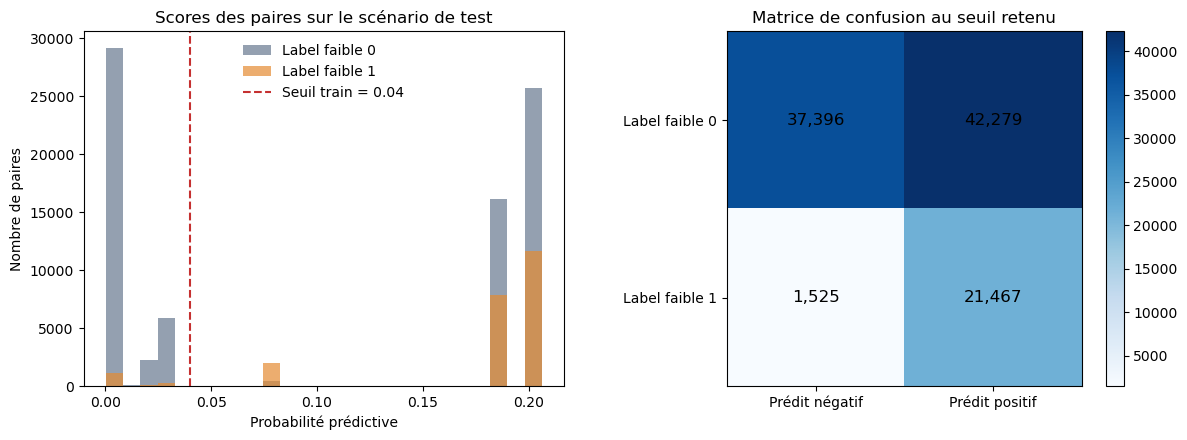

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist([s for s,y in zip(test_scores,test_labels) if y==0], bins=25, alpha=.75, label='Label faible 0', color='#718096')
axes[0].hist([s for s,y in zip(test_scores,test_labels) if y==1], bins=25, alpha=.70, label='Label faible 1', color='#e58b32')
axes[0].axvline(model['decision_threshold'], color='#c53030', linestyle='--', label=f"Seuil train = {model['decision_threshold']:.2f}")
axes[0].set_title('Scores des paires sur le scénario de test')
axes[0].set_xlabel('Probabilité prédictive'); axes[0].set_ylabel('Nombre de paires'); axes[0].legend(frameon=False)
cm=metrics['confusion_matrix']
matrix=[[cm['tn'],cm['fp']],[cm['fn'],cm['tp']]]
img=axes[1].imshow(matrix,cmap='Blues')
axes[1].set_xticks([0,1],['Prédit négatif','Prédit positif'])
axes[1].set_yticks([0,1],['Label faible 0','Label faible 1'])
for i in range(2):
    for j in range(2): axes[1].text(j,i,f'{matrix[i][j]:,}',ha='center',va='center',fontsize=12)
axes[1].set_title('Matrice de confusion au seuil retenu')
fig.colorbar(img,ax=axes[1],fraction=.046)
fig.tight_layout()
plt.show()

## 7. Résumer les métriques sans surinterpréter

- **Précision** : parmi les paires proposées comme positives, part correspondant au label faible positif.
- **Rappel** : part des paires faibles positives retrouvées.
- **F1** : équilibre entre précision et rappel.
- **Average precision (AP)** : qualité du classement des paires à tous les seuils.
- **ROC AUC** : capacité de classement entre les deux classes faibles.

Une précision de `0.337` signifie que de nombreuses paires proposées ne correspondent même pas au proxy temporel. Et une paire qui correspond au proxy n’est pas nécessairement un vrai lien analyste-confirmé. La conclusion raisonnable est : le calcul fonctionne, mais la validation directe des liens n’est pas possible avec ces labels.

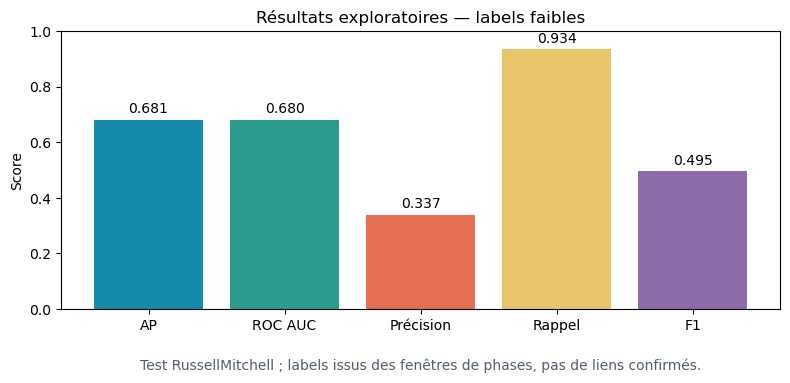

In [12]:
metric_names=['AP','ROC AUC','Précision','Rappel','F1']
metric_values=[metrics['PR_AUC_average_precision'],metrics['ROC_AUC'],metrics['precision'],metrics['recall'],metrics['F1']]
fig, ax = plt.subplots(figsize=(8,4))
bars=ax.bar(metric_names,metric_values,color=['#168aad','#2a9d8f','#e76f51','#e9c46a','#8d6cab'])
ax.set_ylim(0,1); ax.set_ylabel('Score'); ax.set_title('Résultats exploratoires — labels faibles')
ax.bar_label(bars,fmt='%.3f',padding=3)
ax.text(.5,-.22,'Test RussellMitchell ; labels issus des fenêtres de phases, pas de liens confirmés.',
        transform=ax.transAxes,ha='center',color='#52606d')
fig.tight_layout()
plt.show()

## Artefacts produits

- `artifacts/alert_correlation/bayesian_alert_correlation_model.json` : prior, comptes, variables, scénarios et seuil nécessaires au service.
- `artifacts/alert_correlation/validation_metrics.json` : mesures du scénario gardé à part et définition explicite de leur limite.

**Résumé oral possible :** le modèle compare chaque alerte à un petit historique et calcule une probabilité bayésienne pour chaque paire candidate. Le test montre un rappel élevé mais une précision modeste par rapport à un label faible de phase ; il ne prouve pas des corrélations validées par analyste.